# Maximum Likelihood Estimation

Goal: given a sample, find the parameters of an assumed distribution that make the data **most probable**.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats, optimize

plt.rcParams.update({"font.size": 14})

### The data
Imagine 12 measurements corresponding to daily working hours of a sample of workers. We do not know the process that generated them.

[5.37 3.75 5.9  6.13 2.66 3.44 5.15 4.62 4.98 3.98 6.06 5.93]


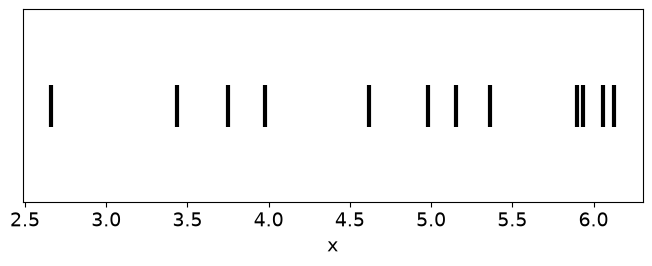

In [2]:
rng = np.random.default_rng(42)
data = rng.normal(loc=5.0, scale=1.2, size=12)   # true values (5.0, 1.2) are hidden from the "analyst"
print(np.round(data, 2))

fig, ax = plt.subplots(figsize=(8, 2.5))
ax.plot(data, np.zeros_like(data), "|", ms=30, mew=3, color="k")
ax.set_yticks([])
ax.set_xlabel("x")
plt.show()

### Choose a model family
Assumption: the data come from a Gaussian generating distribution $p(x;\mu,\sigma)=\frac{1}{\sigma\sqrt{2\pi}}\exp\left(-\frac{(x-\mu)^2}{2\sigma^2}\right)$

- Parameters $\theta=(\mu,\sigma)$ are unknown
- To start, treat $\sigma$ as known and only estimate $\mu$
- MLE question: which $\mu$ makes our data most probable?

### Density of a single point
For a candidate $\mu$, how "likely" is one observation? Just evaluate the density at that point.

In [3]:
sigma = 1.2
x0 = data[0]
for mu in [3.0, 5.0, 7.0]:
    print(f"mu = {mu}:  p(x0 = {x0:.2f}; mu) = {stats.norm.pdf(x0, mu, sigma):.4f}")

mu = 3.0:  p(x0 = 5.37; mu) = 0.0476
mu = 5.0:  p(x0 = 5.37; mu) = 0.3174
mu = 7.0:  p(x0 = 5.37; mu) = 0.1315


Points close to the center of the candidate Gaussian get higher density. Different $\mu$ values rate the same point differently.

### Likelihood of the whole sample
Observations are assumed independent, so the joint density is a product:

$$L(\mu)=\prod_{i=1}^{n} p(x_i;\mu,\sigma)$$

In [4]:
def likelihood(mu, data, sigma=1.2):
    return np.prod(stats.norm.pdf(data, mu, sigma))

for mu in [3.0, 5.0, 7.0]:
    print(f"L(mu = {mu}) = {likelihood(mu, data):.3e}")

L(mu = 3.0) = 1.012e-14
L(mu = 5.0) = 1.033e-08
L(mu = 7.0) = 3.517e-17


The best (largest) of the three candidates is the one closest to the data – but the numbers are very tiny.
Multiplying many small numbers can underflow to 0 in floating point.

### Log-likelihood
Taking $\log$ makes numbers larger and adds computation benefits. $\log$ is increasing, so the maximizer does not change, and the product becomes a sum:

$$\ell(\mu)=\sum_{i=1}^{n}\log p(x_i;\mu,\sigma)$$

In [5]:
def loglik(mu, data, sigma=1.2):
    return stats.norm.logpdf(data, mu, sigma).sum()

for mu in [3.0, 5.0, 7.0]:
    print(f"log L(mu = {mu}) = {loglik(mu, data):.2f}")

log L(mu = 3.0) = -32.22
log L(mu = 5.0) = -18.39
log L(mu = 7.0) = -37.89


### Search for the maximum (grid search)
Evaluate $\ell(\mu)$ on a grid of candidates and pick the best.

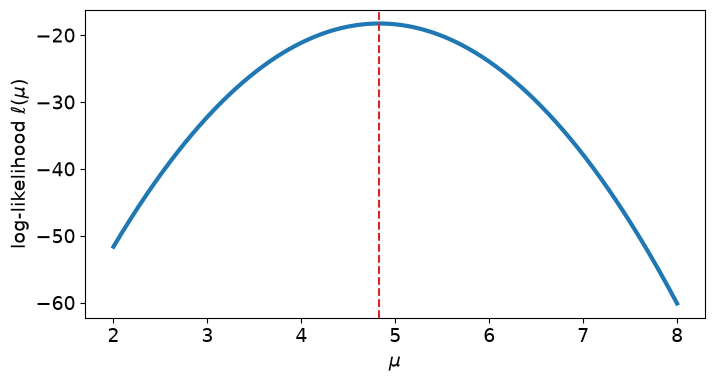

Grid-search MLE: 4.83


In [6]:
grid = np.linspace(2, 8, 601)
ll = np.array([loglik(m, data) for m in grid])
mu_hat_grid = grid[ll.argmax()]

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(grid, ll, lw=3)
ax.axvline(mu_hat_grid, color="C3", ls="--")
ax.set_xlabel(r"$\mu$"); ax.set_ylabel(r"log-likelihood $\ell(\mu)$"); plt.show()
print("Grid-search MLE:", round(mu_hat_grid, 3))

### Closed form (calculus)
Set the derivative to zero:

$$\frac{\partial \ell}{\partial \mu}=\sum_i \frac{x_i-\mu}{\sigma^2}=0\;\Rightarrow\;\hat\mu=\frac1n\sum_i x_i=\bar x$$

The MLE of the Gaussian mean is the sample mean. Check against the grid search:

In [7]:
print("Sample mean      :", round(data.mean(), 3))

Sample mean      : 4.83


In order to estimate the second parameter, set derivative with respect to $\sigma$ to zero. The derivative gives

$$\hat\sigma^2=\frac1n\sum_i (x_i-\hat\mu)^2$$

In [8]:
mu_hat = data.mean()
sigma_hat = np.sqrt(((data - mu_hat) ** 2).mean())
print(f"mu_hat = {mu_hat:.3f}, sigma_hat = {sigma_hat:.3f}   (true: 5.0, 1.2)")

mu_hat = 4.830, sigma_hat = 1.101   (true: 5.0, 1.2)


### Numerical optimization
In most models there is no closed form. We can minimize the negative log-likelihood with an optimizer.

In [9]:
def neg_loglik(theta, data):
    mu, log_sigma = theta                      # optimize log(sigma) so sigma stays positive
    return -stats.norm.logpdf(data, mu, np.exp(log_sigma)).sum()

res = optimize.minimize(neg_loglik, x0=[0.0, 0.0], args=(data,))
print("Optimizer: mu =", round(res.x[0], 3), " sigma =", round(np.exp(res.x[1]), 3))

Optimizer: mu = 4.83  sigma = 1.101


### Visual check of the fitted density

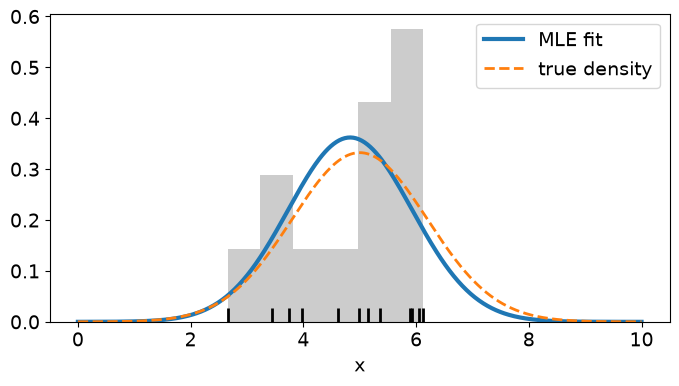

In [10]:
g = np.linspace(0, 10, 400)
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(data, bins=6, density=True, alpha=.4, color="gray")
ax.plot(g, stats.norm.pdf(g, mu_hat, sigma_hat), lw=3, label="MLE fit")
ax.plot(g, stats.norm.pdf(g, 5.0, 1.2), "--", lw=2, label="true density")
ax.plot(data, np.zeros_like(data), "|", ms=20, mew=2, color="k")
ax.legend()
ax.set_xlabel("x")
plt.show()

# From counts to a density estimate

Question: how many trips happen per hour, and how is that quantity distributed?

In [11]:
import pandas as pd

### Load the data

In [12]:
df = pd.read_csv("201306-citibike-tripdata.csv", usecols=["starttime"], parse_dates=["starttime"])

per_hour = df.groupby(df["starttime"].dt.floor("h")).size()
per_hour = per_hour.reindex(pd.date_range(per_hour.index.min(), per_hour.index.max(), freq="h"), fill_value=0)
trips = per_hour.to_numpy()
n = len(trips)
print(f"{n:,} hourly observations; min {trips.min():.0f}, median {np.median(trips):.0f}, max {trips.max():.0f} trips per hour")

721 hourly observations; min 1, median 607, max 3038 trips per hour


Each observation $x_i$ = number of trips in one hour.

### Choose bins and count
Bins of width $h$; the count $c_j$ is the number of observations in bin $j$.

In [13]:
h1 = 500                                        # bin width, in trips per hour
edges1 = np.arange(0, trips.max() + h1, h1)
counts1, _ = np.histogram(trips, bins=edges1)

pd.DataFrame({"bin_start": edges1[:-1], "bin_end": edges1[1:], "count": counts1}).head(8)

,bin_start,bin_end,count
0,0,500,317
1,500,1000,158
2,1000,1500,116
3,1500,2000,65
4,2000,2500,48
5,2500,3000,16
6,3000,3500,1


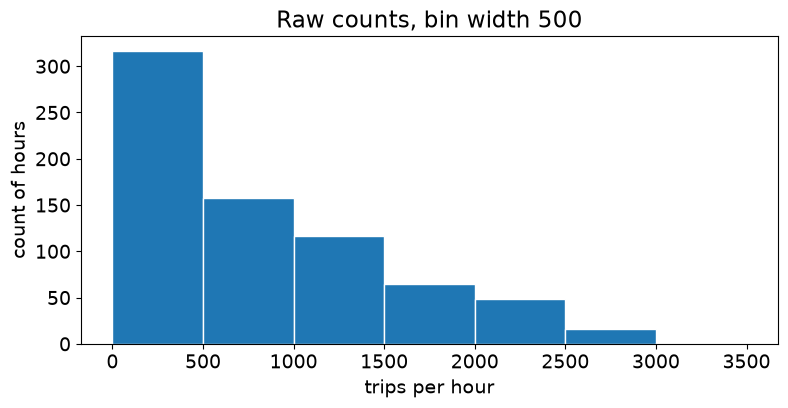

Sum of counts = 721 = number of observations n = 721


In [14]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(edges1[:-1], counts1, width=h1, align="edge", edgecolor="white")
ax.set_xlabel("trips per hour"); ax.set_ylabel("count of hours"); ax.set_title(f"Raw counts, bin width {h1}")
plt.show()
print("Sum of counts =", counts1.sum(), "= number of observations n =", n)

### Divide by the number of observations
Relative frequency of a bin: $\; \hat p_j = \frac{c_j}{n}$

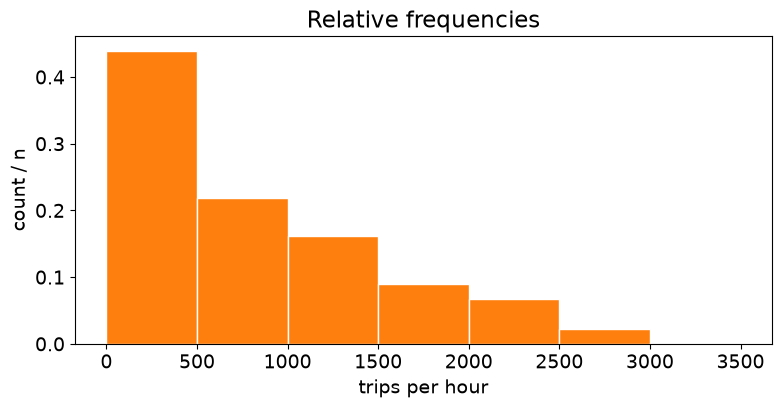

Sum of bar HEIGHTS : 1.0
AREA of the bars   : 500.0   (= bin width 500, not 1!)


In [15]:
rel1 = counts1 / n

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(edges1[:-1], rel1, width=h1, align="edge", edgecolor="white", color="C1")
ax.set_xlabel("trips per hour"); ax.set_ylabel("count / n"); ax.set_title("Relative frequencies")
plt.show()

print("Sum of bar HEIGHTS :", rel1.sum().round(4))
print("AREA of the bars   :", (rel1 * h1).sum().round(4), f"  (= bin width {h1}, not 1!)")

The heights add up to 1 – this is a probability per bin.
But a density must have area 1, since probabilities are areas: $\int p(x)\,dx = 1$.
Here the area equals the bin width, so this is not a density.

### Also divide by the bin width
$$\hat p(x) = \frac{c_j}{n\cdot h} \quad\text{for } x \text{ in bin } j$$

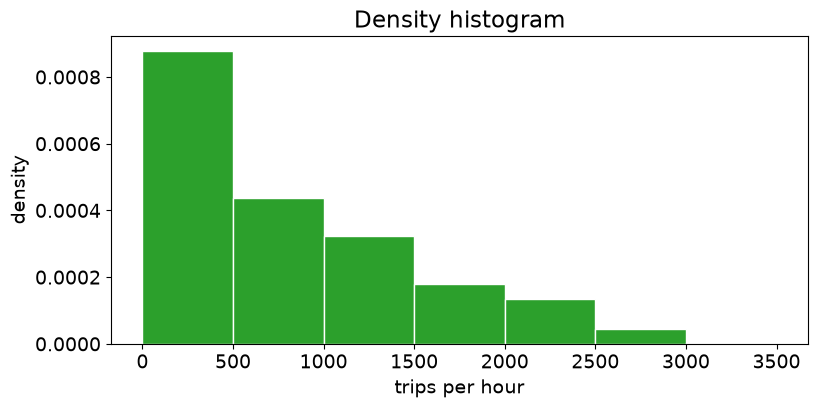

Sum of bar heights: 0.002 (no longer 1 - and that is fine)
AREA of the bars  : 1.0


In [16]:
dens1 = counts1 / (n * h1)

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(edges1[:-1], dens1, width=h1, align="edge", edgecolor="white", color="C2")
ax.set_xlabel("trips per hour"); ax.set_ylabel("density"); ax.set_title("Density histogram")
plt.show()

print("Sum of bar heights:", dens1.sum().round(6), "(no longer 1 - and that is fine)")
print("AREA of the bars  :", (dens1 * h1).sum().round(6))

In [17]:
# Same thing from numpy:
dens_np, _ = np.histogram(trips, bins=edges1, density=True)
print("Matches np.histogram(density=True):", np.allclose(dens1, dens_np))

Matches np.histogram(density=True): True


### Another bin width
Same data, bins 4 times wider.

In [18]:
h2 = 2000
edges2 = np.arange(0, trips.max() + h2, h2)
counts2, _ = np.histogram(trips, bins=edges2)
rel2  = counts2 / n
dens2 = counts2 / (n * h2)

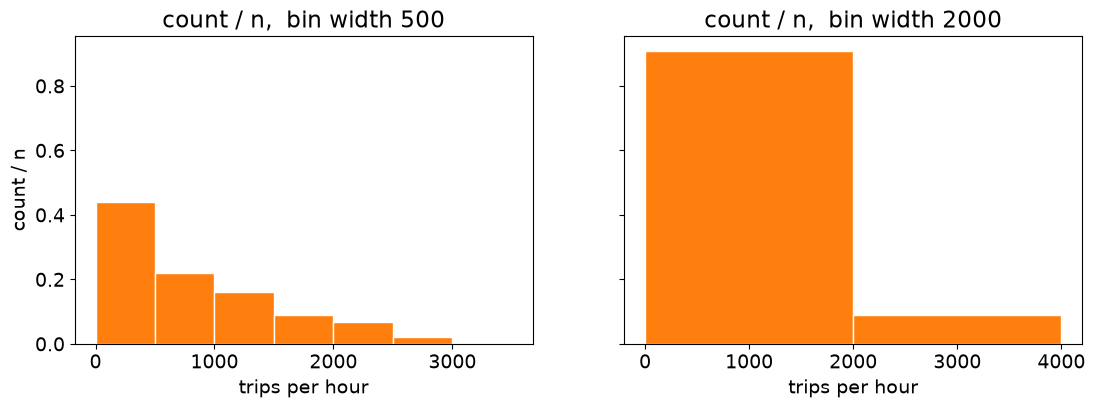

In [19]:
# Relative frequencies: bar heights depend on the bin width
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, e, r, h in [(axes[0], edges1, rel1, h1), (axes[1], edges2, rel2, h2)]:
    ax.bar(e[:-1], r, width=h, align="edge", edgecolor="white", color="C1")
    ax.set_title(f"count / n,  bin width {h}"); ax.set_xlabel("trips per hour")
axes[0].set_ylabel("count / n")
plt.show()

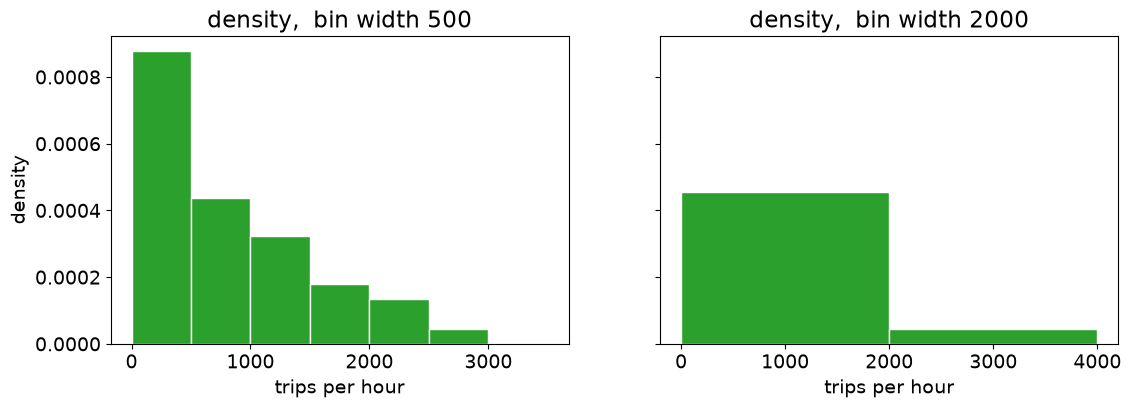

In [20]:
# Density: same scale, comparable shapes
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, e, d, h in [(axes[0], edges1, dens1, h1), (axes[1], edges2, dens2, h2)]:
    ax.bar(e[:-1], d, width=h, align="edge", edgecolor="white", color="C2")
    ax.set_title(f"density,  bin width {h}"); ax.set_xlabel("trips per hour")
axes[0].set_ylabel("density")
plt.show()

# Gaussian kernel density estimate

Histograms depend on bin edges and bin width, and look blocky. Idea: put a smooth bump on every observation and add them up.

In [21]:
print(f"n = {n:,} hourly observations, std = {trips.std():.0f}")

n = 721 hourly observations, std = 735


### The Gaussian kernel
$$K(u)=\frac{1}{\sqrt{2\pi}}\,e^{-u^2/2}$$

A symmetric bump, area 1, centered at 0. Written as a function:

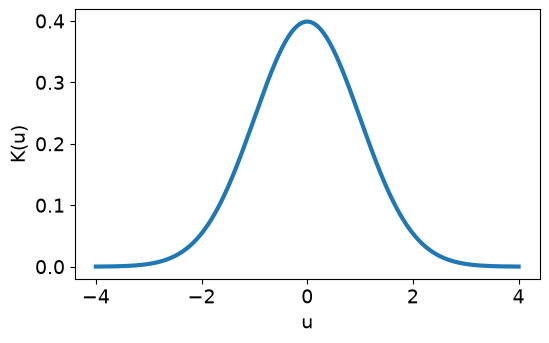

Area under K: 0.9999


In [22]:
def K(u):
    return np.exp(-u**2 / 2) / np.sqrt(2 * np.pi)

u = np.linspace(-4, 4, 400)
plt.figure(figsize=(6, 3.5)); plt.plot(u, K(u), lw=3); plt.xlabel("u"); plt.ylabel("K(u)"); plt.show()
print("Area under K:", np.trapezoid(K(u), u).round(4))

### A bump for one observation, with bandwidth $h$
Center the kernel at an observation $x_i$ and stretch it by the bandwidth $h$:

$$\frac{1}{h}\,K\!\left(\frac{x-x_i}{h}\right)$$

(the factor $1/h$ keeps the area at 1)

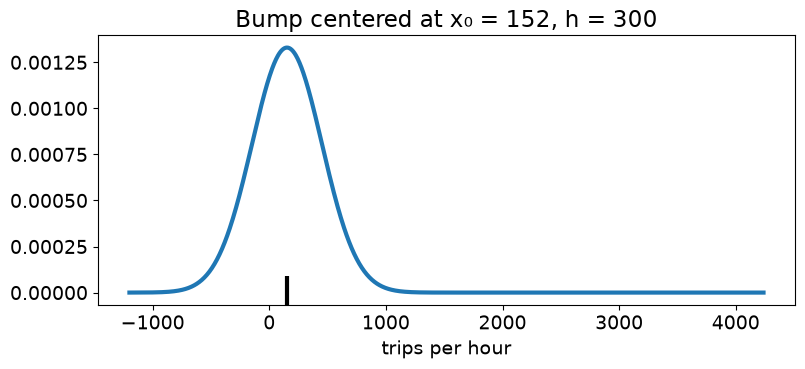

Area of the bump: 1.0


In [23]:
h = 300
xi = trips[0]
grid = np.linspace(trips.min() - 4 * h, trips.max() + 4 * h, 1000)

bump = K((grid - xi) / h) / h
plt.figure(figsize=(9, 3.5))
plt.plot(grid, bump, lw=3); plt.plot(xi, 0, "k|", ms=25, mew=3)
plt.xlabel("trips per hour")
plt.title(f"Bump centered at x₀ = {xi:.0f}, h = {h}")
plt.show()
print("Area of the bump:", np.trapezoid(bump, grid).round(4))

### Add the bumps – a small sample first
Take 6 observations, one bump each; each bump has area $1/6$ so the sum has area 1.

$$\hat p(x)=\frac{1}{n}\sum_{i=1}^{n}\frac1h K\!\left(\frac{x-x_i}{h}\right)$$

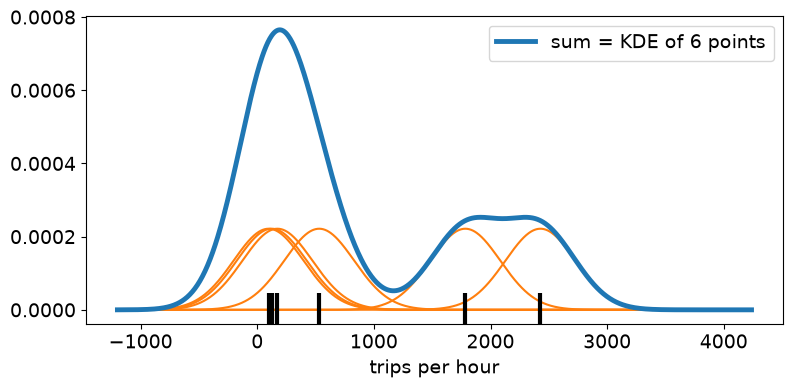

Area under the sum: 1.0


In [24]:
small = np.random.default_rng(1).choice(trips, 6, replace=False)
bumps = np.array([K((grid - xi) / h) / h / len(small) for xi in small])

plt.figure(figsize=(9, 4))
for b in bumps:
    plt.plot(grid, b, color="C1", lw=1.5)
plt.plot(grid, bumps.sum(axis=0), color="C0", lw=3.5, label="sum = KDE of 6 points")
plt.plot(small, np.zeros_like(small), "k|", ms=25, mew=3)
plt.xlabel("trips per hour")
plt.legend()
plt.show()
print("Area under the sum:", np.trapezoid(bumps.sum(axis=0), grid).round(4))

### KDE from scratch for all observations
Rows = grid points, columns = observations; the whole thing is one line.

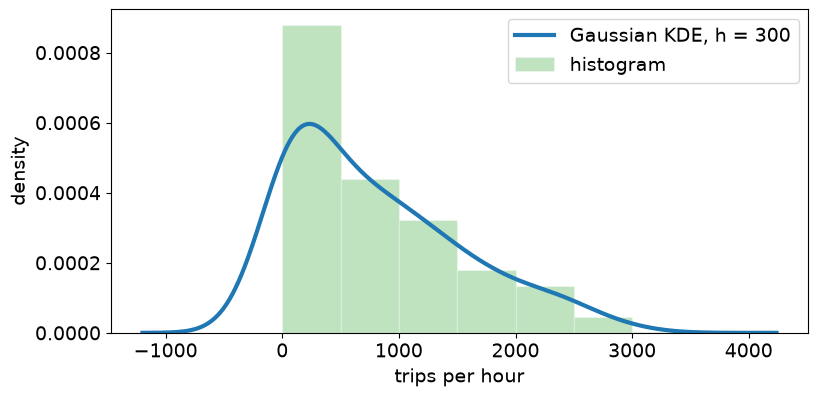

Area under the KDE: 1.0


In [25]:
def kde(x, data, h):
    u = (x[:, None] - data[None, :]) / h          # shape (grid, n)
    return K(u).sum(axis=1) / (len(data) * h)

p_hat = kde(grid, trips, h=300)

fig, ax = plt.subplots(figsize=(9, 4.2))
ax.bar(edges1[:-1], dens_np, width=h1, align="edge", color="C2", alpha=.3, edgecolor="white", label="histogram")
ax.plot(grid, p_hat, lw=3, color="C0", label="Gaussian KDE, h = 300")
ax.set_xlabel("trips per hour")
ax.set_ylabel("density")
ax.legend()
plt.show()

print("Area under the KDE:", np.trapezoid(p_hat, grid).round(4))

In [26]:
# `gaussian_kde` takes the bandwidth as a factor of the data's standard deviation, we convert: $h = \text{factor}\cdot\sigma$.
p_scipy = stats.gaussian_kde(trips, bw_method=300 / trips.std(ddof=1))(grid)
print("Matches scipy:", np.allclose(p_hat, p_scipy))

Matches scipy: True


### The bandwidth controls the smoothness

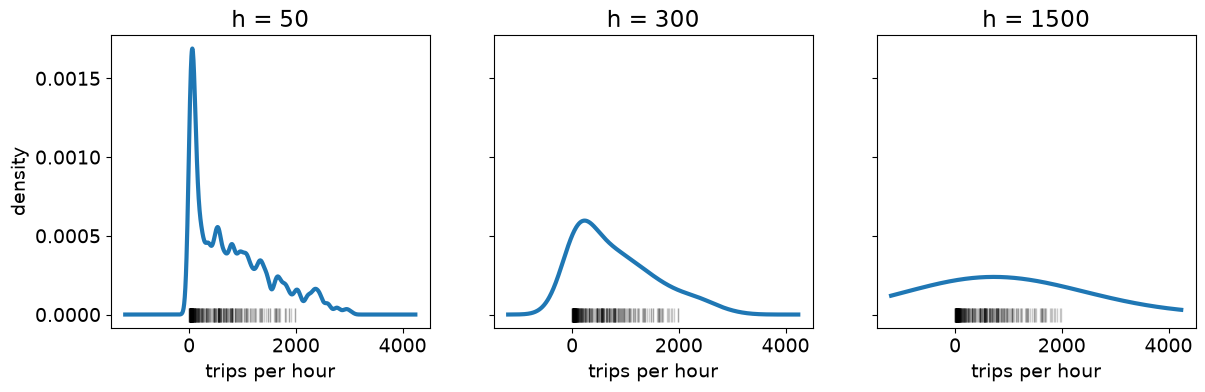

In [27]:
hs = [50, 300, 1500]
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), sharey=True)
for ax, hh in zip(axes, hs):
    ax.plot(grid, kde(grid, trips, hh), lw=3)
    ax.plot(trips[:300], np.zeros(min(300, n)), "k|", alpha=.2, ms=10)
    ax.set_title(f"h = {hh}"); ax.set_xlabel("trips per hour")
axes[0].set_ylabel("density"); plt.show()

- small $h$: spiky, follows individual observations (high variance)
- large $h$: over-smoothed, the separate peaks disappear (high bias)

Same trade-off as the histogram's bin width – but now the result does not depend on where bins start.